In [34]:
# Sel 1 - Setup, parameter, validasi, dan autentikasi Earth Engine
!pip install -q geemap

import datetime

import ee
import geemap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import output

output.enable_custom_widget_manager()

# ===== PARAMETER (ubah di sini saja) =====
PROJECT_ID       = "gen-lang-client-0768750078"   # Google Cloud project yang terdaftar Earth Engine
TAHUN_ANALISIS   = [2015, 2020, 2025]
SENSOR           = "landsat"               # "landsat" (30 m) atau "sentinel2" (10 m, disarankan >= 2019)
BULAN_AWAL       = 1
BULAN_AKHIR      = 12
MODE_SAMPEL      = "otomatis"              # "otomatis" (ESA WorldCover) atau "manual" (asset titik sendiri)
ASSET_SAMPEL     = ""                      # wajib jika manual; titik dengan atribut integer 'kelas'
ASSET_BATAS      = ""                      # kosong = FAO GAUL 2025; isi path asset batas resmi jika ada
FOLDER_DRIVE     = "GEE_HSS_Tutupan_Lahan"
CRS_EKSPOR       = "EPSG:32750"            # UTM Zona 50S
JUMLAH_POHON_RF  = 150
SAMPEL_PER_KELAS = 400
SEED             = 42
NAMA_PENYUSUN    = "Agung Laksono, S.Hut"
INSTANSI         = "Program Magister Kehutanan, Universitas Lambung Mangkurat"
JUDUL_LAPORAN    = "Analisis Perubahan Tutupan Lahan Kabupaten Hulu Sungai Selatan"

# Tahun komposit acuan pelatihan (tahun WorldCover v200). Pada mode manual,
# titik sampel juga dibaca pada komposit tahun ini.
TAHUN_ACUAN = 2021

# ===== VALIDASI PARAMETER =====
kesalahan = []
tahun_ini = datetime.date.today().year
if not PROJECT_ID or PROJECT_ID == "isi-project-id-anda":
    kesalahan.append("PROJECT_ID belum diisi dengan ID project Google Cloud Anda.")
if SENSOR not in ("landsat", "sentinel2"):
    kesalahan.append("SENSOR harus 'landsat' atau 'sentinel2'.")
if MODE_SAMPEL not in ("otomatis", "manual"):
    kesalahan.append("MODE_SAMPEL harus 'otomatis' atau 'manual'.")
if MODE_SAMPEL == "manual" and not ASSET_SAMPEL:
    kesalahan.append("MODE_SAMPEL = 'manual' mewajibkan ASSET_SAMPEL diisi.")
if not (1 <= BULAN_AWAL <= BULAN_AKHIR <= 12):
    kesalahan.append("BULAN_AWAL dan BULAN_AKHIR harus 1-12, dan BULAN_AWAL <= BULAN_AKHIR.")
if len(set(TAHUN_ANALISIS)) < 2:
    kesalahan.append("TAHUN_ANALISIS perlu minimal 2 tahun berbeda untuk matriks perubahan.")
if any(t > tahun_ini for t in TAHUN_ANALISIS):
    kesalahan.append(f"TAHUN_ANALISIS tidak boleh melebihi tahun berjalan ({tahun_ini}).")
if SENSOR == "sentinel2" and any(t < 2019 for t in TAHUN_ANALISIS):
    kesalahan.append("Sentinel-2 hanya untuk tahun >= 2019. Pakai SENSOR = 'landsat' untuk tahun lebih lama.")
if SENSOR == "landsat" and any(t < 1984 for t in TAHUN_ANALISIS):
    kesalahan.append("Landsat Collection 2 pada notebook ini hanya untuk tahun >= 1984.")
if kesalahan:
    raise ValueError("Parameter belum benar:\n- " + "\n- ".join(kesalahan))

TAHUN_ANALISIS = sorted(set(TAHUN_ANALISIS))

# ===== AUTENTIKASI =====
ee.Authenticate()
try:
    ee.Initialize(project=PROJECT_ID)
except Exception as galat:
    raise RuntimeError(
        f"Gagal inisialisasi Earth Engine untuk project '{PROJECT_ID}'. "
        f"Pastikan project terdaftar Earth Engine dan akun Anda punya akses.\nDetail: {galat}"
    ) from galat

# Penampung semua angka dan tabel untuk laporan PDF di Sel 13
HASIL = {}

# ===== KONSTANTA ANALISIS =====
SKALA = 30 if SENSOR == "landsat" else 10
BANDS = ["blue", "green", "red", "nir", "swir1", "swir2",
         "NDVI", "NDWI", "MNDWI", "NDBI", "EVI", "elevation", "slope"]

# ===== DICTIONARY KELAS (satu sumber untuk peta, legenda, tabel, dan grafik) =====
KELAS_OTOMATIS = {
    1: {"nama": "Hutan/tutupan pohon",        "warna": "#1B7837"},
    2: {"nama": "Semak belukar & rumput",     "warna": "#A6D96A"},
    3: {"nama": "Pertanian",                  "warna": "#F4D03F"},
    4: {"nama": "Rawa/lahan basah herba",     "warna": "#45B39D"},
    5: {"nama": "Lahan terbangun",            "warna": "#D73027"},
    6: {"nama": "Lahan terbuka",              "warna": "#BFA58A"},
    7: {"nama": "Tubuh air",                  "warna": "#2166AC"},
}
KELAS_MANUAL = {
    1:  {"nama": "Hutan lahan kering",          "warna": "#1B7837"},
    2:  {"nama": "Hutan rawa",                  "warna": "#2E8B8B"},
    3:  {"nama": "Semak belukar",               "warna": "#A6D96A"},
    4:  {"nama": "Perkebunan/kebun campuran",   "warna": "#7B9E2F"},
    5:  {"nama": "Pertanian lahan kering",      "warna": "#F4D03F"},
    6:  {"nama": "Sawah",                       "warna": "#F39C12"},
    7:  {"nama": "Rawa",                        "warna": "#45B39D"},
    8:  {"nama": "Permukiman/lahan terbangun",  "warna": "#D73027"},
    9:  {"nama": "Lahan terbuka/tambang",       "warna": "#BFA58A"},
    10: {"nama": "Tubuh air",                   "warna": "#2166AC"},
}
KELAS       = KELAS_OTOMATIS if MODE_SAMPEL == "otomatis" else KELAS_MANUAL
KODE_KELAS  = sorted(KELAS)
NAMA_KELAS  = [KELAS[k]["nama"] for k in KODE_KELAS]
WARNA_KELAS = [KELAS[k]["warna"] for k in KODE_KELAS]
VIS_KELAS   = {"min": min(KODE_KELAS), "max": max(KODE_KELAS),
               "palette": [w.lstrip("#") for w in WARNA_KELAS]}
VIS_TRUE    = {"bands": ["red", "green", "blue"], "min": 0.0, "max": 0.3, "gamma": 1.2}


def ambil_info(objek_ee, pesan="mengambil hasil dari Earth Engine"):
    """Satu pintu getInfo() untuk hasil kecil, dengan pesan error yang mudah dipahami."""
    try:
        return objek_ee.getInfo()
    except Exception as galat:
        raise RuntimeError(
            f"[GAGAL] Gagal saat {pesan}.\nDetail Earth Engine: {galat}\n"
            "Saran: jalankan ulang sel ini. Jika 'timed out' atau 'memory limit', "
            "pakai ekspor di Sel 12 atau kurangi cakupan analisis."
        ) from galat


print(f"[OK] Earth Engine aktif | sensor={SENSOR} | skala={SKALA} m | mode={MODE_SAMPEL} | tahun={TAHUN_ANALISIS}")

[OK] Earth Engine aktif | sensor=landsat | skala=30 m | mode=otomatis | tahun=[2015, 2020, 2025]


In [35]:
# Sel 2 - Batas wilayah Kabupaten Hulu Sungai Selatan
if ASSET_BATAS:
    fc_batas = ee.FeatureCollection(ASSET_BATAS)
    sumber_batas = ASSET_BATAS
else:
    gaul_indonesia = (ee.FeatureCollection("FAO/GAUL/2025/level2")
                      .filter(ee.Filter.eq("GAUL0_NAME", "Indonesia")))
    fc_batas = gaul_indonesia.filter(ee.Filter.stringContains("GAUL2_NAME", "Hulu Sungai Selatan"))
    sumber_batas = "FAO/GAUL/2025/level2"

jumlah_fitur = ambil_info(fc_batas.size(), "menghitung jumlah fitur batas")
print(f"Sumber batas : {sumber_batas}")
print(f"Jumlah fitur : {jumlah_fitur}")

if jumlah_fitur == 0:
    if not ASSET_BATAS:
        nama_hulu = ambil_info(
            gaul_indonesia.filter(ee.Filter.stringContains("GAUL2_NAME", "Hulu"))
                          .aggregate_array("GAUL2_NAME").distinct(),
            "mencari ejaan nama wilayah di GAUL",
        )
        print("Nama GAUL2_NAME yang mengandung 'Hulu':", nama_hulu)
    raise ValueError(
        "Batas wilayah tidak ditemukan (0 fitur). Periksa ejaan nama di atas, "
        "atau isi ASSET_BATAS dengan asset batas resmi."
    )

aoi = fc_batas.geometry()
luas_aoi_km2 = ambil_info(aoi.area(maxError=1).divide(1e6), "menghitung luas wilayah")
print(f"Luas wilayah : {luas_aoi_km2:,.1f} km²")
if not 1200 <= luas_aoi_km2 <= 2400:
    print("[PERINGATAN] Luas jauh dari perkiraan ±1.800 km². Periksa kembali batas wilayah.")
HASIL["luas_wilayah_km2"] = luas_aoi_km2
HASIL["sumber_batas"] = sumber_batas
print("[OK] Batas wilayah siap")

Sumber batas : FAO/GAUL/2025/level2
Jumlah fitur : 1
Luas wilayah : 1,705.8 km²
[OK] Batas wilayah siap


In [36]:
# Sel 3 - Fungsi praproses citra, indeks, dan topografi
BAND_SERAGAM = ["blue", "green", "red", "nir", "swir1", "swir2"]
BAND_OLI = ["SR_B2", "SR_B3", "SR_B4", "SR_B5", "SR_B6", "SR_B7"]   # Landsat 8/9
BAND_TM  = ["SR_B1", "SR_B2", "SR_B3", "SR_B4", "SR_B5", "SR_B7"]   # Landsat 5/7
BAND_S2  = ["B2", "B3", "B4", "B8", "B11", "B12"]

# QA_PIXEL: bit 1 dilated cloud, bit 2 cirrus (khusus L8/L9), bit 3 cloud, bit 4 shadow
MASK_QA_TM  = (1 << 1) | (1 << 3) | (1 << 4)
MASK_QA_OLI = MASK_QA_TM | (1 << 2)
AMBANG_CS   = 0.60


def praproses_oli(img):
    """Landsat 8/9: mask awan, skala reflektansi, nama band seragam."""
    mask = img.select("QA_PIXEL").bitwiseAnd(MASK_QA_OLI).eq(0)
    hasil = img.select(BAND_OLI, BAND_SERAGAM).multiply(0.0000275).add(-0.2).updateMask(mask)
    return ee.Image(hasil.copyProperties(img, ["system:time_start"]))


def praproses_tm(img):
    """Landsat 5/7: mask awan, skala reflektansi, nama band seragam."""
    mask = img.select("QA_PIXEL").bitwiseAnd(MASK_QA_TM).eq(0)
    hasil = img.select(BAND_TM, BAND_SERAGAM).multiply(0.0000275).add(-0.2).updateMask(mask)
    return ee.Image(hasil.copyProperties(img, ["system:time_start"]))


def praproses_s2(img):
    """Sentinel-2: mask Cloud Score+, skala reflektansi, nama band seragam."""
    mask = img.select("cs_cdf").gte(AMBANG_CS)
    hasil = img.select(BAND_S2, BAND_SERAGAM).divide(10000).updateMask(mask)
    return ee.Image(hasil.copyProperties(img, ["system:time_start"]))


def saring_koleksi(id_koleksi, tahun_awal, tahun_akhir):
    """Saring koleksi menurut wilayah, rentang tahun, dan bulan."""
    return (ee.ImageCollection(id_koleksi)
            .filterBounds(aoi)
            .filterDate(f"{tahun_awal}-01-01", f"{tahun_akhir + 1}-01-01")
            .filter(ee.Filter.calendarRange(BULAN_AWAL, BULAN_AKHIR, "month")))


def koleksi_landsat(tahun_awal, tahun_akhir):
    """L8/L9 untuk periode >= 2013, L5/L7 untuk periode < 2013."""
    bagian = []
    if tahun_akhir >= 2013:
        bagian.append(saring_koleksi("LANDSAT/LC08/C02/T1_L2", tahun_awal, tahun_akhir).map(praproses_oli))
        bagian.append(saring_koleksi("LANDSAT/LC09/C02/T1_L2", tahun_awal, tahun_akhir).map(praproses_oli))
    if tahun_awal < 2013:
        bagian.append(saring_koleksi("LANDSAT/LT05/C02/T1_L2", tahun_awal, tahun_akhir).map(praproses_tm))
        bagian.append(saring_koleksi("LANDSAT/LE07/C02/T1_L2", tahun_awal, tahun_akhir).map(praproses_tm))
    gabungan = bagian[0]
    for koleksi in bagian[1:]:
        gabungan = gabungan.merge(koleksi)
    return gabungan


def koleksi_sentinel2(tahun_awal, tahun_akhir):
    """Sentinel-2 SR Harmonized yang ditautkan dengan Cloud Score+."""
    cs_plus = ee.ImageCollection("GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED")
    tertaut = saring_koleksi("COPERNICUS/S2_SR_HARMONIZED", tahun_awal, tahun_akhir).linkCollection(cs_plus, ["cs_cdf"])
    return ee.ImageCollection(tertaut).map(praproses_s2)


def ambil_koleksi(tahun_awal, tahun_akhir):
    if SENSOR == "landsat":
        return koleksi_landsat(tahun_awal, tahun_akhir)
    return koleksi_sentinel2(tahun_awal, tahun_akhir)


def tambah_indeks(img):
    """Tambahkan NDVI, NDWI, MNDWI, NDBI, dan EVI."""
    ndvi  = img.normalizedDifference(["nir", "red"]).rename("NDVI")
    ndwi  = img.normalizedDifference(["green", "nir"]).rename("NDWI")
    mndwi = img.normalizedDifference(["green", "swir1"]).rename("MNDWI")
    ndbi  = img.normalizedDifference(["swir1", "nir"]).rename("NDBI")
    evi = img.expression(
        "2.5 * (NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1)",
        {"NIR": img.select("nir"), "RED": img.select("red"), "BLUE": img.select("blue")},
    ).rename("EVI")
    return img.addBands([ndvi, ndwi, mndwi, ndbi, evi])


dem = ee.Image("USGS/SRTMGL1_003").select("elevation")
TOPOGRAFI = dem.addBands(ee.Terrain.slope(dem))
print("[OK] Fungsi praproses siap")

[OK] Fungsi praproses siap


In [37]:
# Sel 4 - Komposit tahunan dengan pengisian celah awan
def persen_valid(img):
    """Persentase piksel valid di dalam aoi (angka server-side)."""
    statistik = img.select("nir").mask().rename("valid").reduceRegion(
        reducer=ee.Reducer.mean(), geometry=aoi, scale=SKALA, maxPixels=1e13, tileScale=4)
    return ee.Number(statistik.get("valid")).multiply(100)


def buat_komposit(tahun):
    koleksi_utama = ambil_koleksi(tahun, tahun)
    jumlah_citra = ambil_info(koleksi_utama.size(), f"menghitung jumlah citra {tahun}")
    if jumlah_citra == 0:
        raise ValueError(
            f"Tidak ada citra {SENSOR} untuk tahun {tahun}, bulan {BULAN_AWAL}-{BULAN_AKHIR}. "
            "Perlebar rentang bulan atau ganti tahun."
        )
    utama = koleksi_utama.median()
    # Median tahun-1 s.d. tahun+1 mengisi celah awan. sameFootprint=False agar
    # area pengisi tidak terpotong oleh footprint citra utama.
    pengisi = ambil_koleksi(tahun - 1, tahun + 1).median()
    terisi = utama.unmask(pengisi, sameFootprint=False)

    persen = ambil_info(
        ee.Dictionary({"utama": persen_valid(utama), "terisi": persen_valid(terisi)}),
        f"menghitung persentase piksel valid {tahun}",
    )
    # Indeks dihitung setelah celah terisi agar semua band konsisten.
    citra = tambah_indeks(terisi).addBands(TOPOGRAFI).select(BANDS).toFloat().clip(aoi)
    return citra, {"tahun": tahun, "jumlah_citra": jumlah_citra,
                   "valid_tahun_ini_%": round(persen["utama"], 2),
                   "valid_setelah_diisi_%": round(persen["terisi"], 2)}


komposit = {}
ringkasan_komposit = []
for tahun in sorted(set(TAHUN_ANALISIS + [TAHUN_ACUAN])):
    komposit[tahun], info_komposit = buat_komposit(tahun)
    ringkasan_komposit.append(info_komposit)
    print(f"[OK] Komposit {tahun} selesai")

HASIL["df_komposit"] = pd.DataFrame(ringkasan_komposit).set_index("tahun")
display(HASIL["df_komposit"])

# Peta dasar Esri, bukan OpenStreetMap (tile OSM diblokir 403 dari Colab)
peta_komposit = geemap.Map(basemap="Esri.WorldImagery")
peta_komposit.centerObject(fc_batas, 10)
for tahun in TAHUN_ANALISIS:
    peta_komposit.addLayer(komposit[tahun], VIS_TRUE, f"True color {tahun}", tahun == TAHUN_ANALISIS[-1])
peta_komposit

[OK] Komposit 2015 selesai
[OK] Komposit 2020 selesai
[OK] Komposit 2021 selesai
[OK] Komposit 2025 selesai


,jumlah_citra,valid_tahun_ini_%,valid_setelah_diisi_%
tahun,,,
2015,43,100.00,100.00
2020,38,98.97,99.89
2021,41,99.46,99.98
2025,76,99.97,100.00


Map(center=[-2.7284204710301867, 115.20695676099912], controls=(WidgetControl(options=['position', 'transparen…

In [38]:
# Sel 5 - Data latih dan data uji
if MODE_SAMPEL == "otomatis":
    print("CATATAN: mode otomatis cocok untuk eksplorasi. Untuk hasil ilmiah final, pakai sampel "
          "manual atau data lapangan, karena kebun (sawit/karet) bisa tergabung ke kelas 1.")
    label = (ee.ImageCollection("ESA/WorldCover/v200").first().select("Map")
             .remap([10, 95, 20, 30, 40, 90, 50, 60, 80],
                    [1,  1,  2,  2,  3,  4,  5,  6,  7])
             .rename("kelas").toInt())
    homogen = label.focalMax(1).eq(label.focalMin(1))
    citra_sampel = komposit[TAHUN_ACUAN].select(BANDS).addBands(label.updateMask(homogen))
    sampel = citra_sampel.stratifiedSample(
        numPoints=SAMPEL_PER_KELAS, classBand="kelas", region=aoi,
        scale=SKALA, seed=SEED, geometries=True, tileScale=4)
else:
    print(f"Mode manual: titik sampel dibaca pada komposit {TAHUN_ACUAN}. "
          "Pastikan label titik mewakili kondisi tahun tersebut.")
    titik_sampel = ee.FeatureCollection(ASSET_SAMPEL)
    sampel = komposit[TAHUN_ACUAN].select(BANDS).sampleRegions(
        collection=titik_sampel, properties=["kelas"],
        scale=SKALA, tileScale=4, geometries=True)

sampel = sampel.randomColumn(seed=SEED)
data_latih = sampel.filter(ee.Filter.lt("random", 0.7))
data_uji   = sampel.filter(ee.Filter.gte("random", 0.7))

histogram = ambil_info(sampel.aggregate_histogram("kelas"), "menghitung jumlah sampel per kelas")
jumlah_sampel = {int(float(k)): int(v) for k, v in histogram.items()}
if not jumlah_sampel:
    raise ValueError("Tidak ada sampel yang terambil. Periksa komposit, batas wilayah, dan asset sampel.")

display(pd.DataFrame({
    "kelas": NAMA_KELAS,
    "jumlah_sampel": [jumlah_sampel.get(k, 0) for k in KODE_KELAS],
}, index=KODE_KELAS))

kode_asing = sorted(set(jumlah_sampel) - set(KODE_KELAS))
if kode_asing:
    print(f"[PERINGATAN] Ada kode kelas di luar skema aktif: {kode_asing}. Perbaiki atribut 'kelas' pada sampel.")
for kode in KODE_KELAS:
    if jumlah_sampel.get(kode, 0) < 30:
        print(f"[PERINGATAN] Kelas {kode} ({KELAS[kode]['nama']}) hanya punya "
              f"{jumlah_sampel.get(kode, 0)} sampel (< 30). Akurasinya tidak andal.")

pembagian = ambil_info(
    ee.Dictionary({"latih": data_latih.aggregate_histogram("kelas"), "uji": data_uji.aggregate_histogram("kelas")}),
    "menghitung pembagian sampel",
)
latih_per_kelas = {int(float(k)): int(v) for k, v in pembagian["latih"].items()}
uji_per_kelas = {int(float(k)): int(v) for k, v in pembagian["uji"].items()}
HASIL["df_sampel"] = pd.DataFrame({
    "latih": [latih_per_kelas.get(k, 0) for k in KODE_KELAS],
    "uji": [uji_per_kelas.get(k, 0) for k in KODE_KELAS],
}, index=NAMA_KELAS)
print(f"[OK] Data siap | latih={HASIL['df_sampel']['latih'].sum()} | uji={HASIL['df_sampel']['uji'].sum()}")

CATATAN: mode otomatis cocok untuk eksplorasi. Untuk hasil ilmiah final, pakai sampel manual atau data lapangan, karena kebun (sawit/karet) bisa tergabung ke kelas 1.


,kelas,jumlah_sampel
1,Hutan/tutupan pohon,400
2,Semak belukar & rumput,400
3,Pertanian,400
4,Rawa/lahan basah herba,400
5,Lahan terbangun,400
6,Lahan terbuka,400
7,Tubuh air,400


[OK] Data siap | latih=1960 | uji=840


Overall accuracy : 0.8500
Kappa            : 0.8250


,Hutan/tutupan pohon,Semak belukar & rumput,Pertanian,Rawa/lahan basah herba,Lahan terbangun,Lahan terbuka,Tubuh air
Hutan/tutupan pohon,110,4,2,2,0,0,0
Semak belukar & rumput,3,99,7,18,0,0,0
Pertanian,2,9,85,20,4,0,1
Rawa/lahan basah herba,0,8,22,78,3,0,6
Lahan terbangun,0,1,1,1,108,0,0
Lahan terbuka,0,0,0,0,0,114,0
Tubuh air,0,0,2,10,0,0,120


,producers_accuracy,users_accuracy
Hutan/tutupan pohon,0.9322,0.9565
Semak belukar & rumput,0.7795,0.8182
Pertanian,0.7025,0.7143
Rawa/lahan basah herba,0.6667,0.6047
Lahan terbangun,0.9730,0.9391
Lahan terbuka,1.0000,1.0000
Tubuh air,0.9091,0.9449


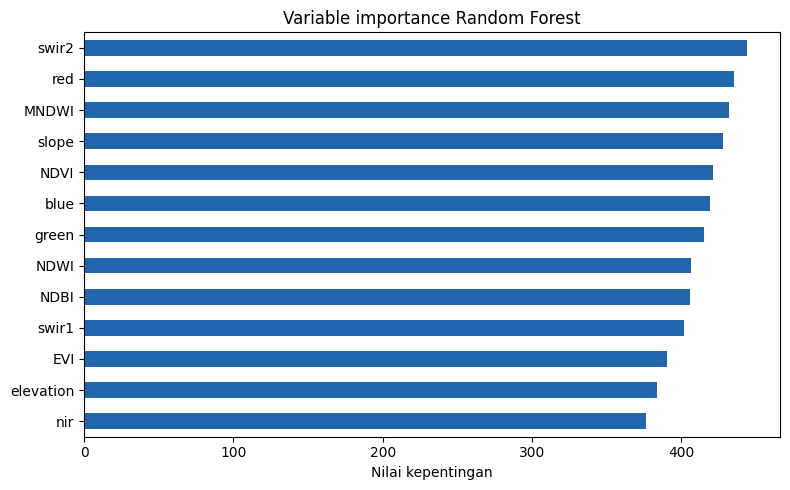

[OK] Model selesai dilatih dan dinilai


In [39]:
# Sel 6 - Random Forest, akurasi, dan variable importance
model = ee.Classifier.smileRandomForest(numberOfTrees=JUMLAH_POHON_RF, seed=SEED).train(
    features=data_latih, classProperty="kelas", inputProperties=BANDS)

matriks_error = data_uji.classify(model).errorMatrix("kelas", "classification", KODE_KELAS)
akurasi = ambil_info(ee.Dictionary({
    "matriks": matriks_error.array(),
    "oa": matriks_error.accuracy(),
    "kappa": matriks_error.kappa(),
    "pa": matriks_error.producersAccuracy(),
    "ua": matriks_error.consumersAccuracy(),
}), "menghitung akurasi data uji")

print(f"Overall accuracy : {akurasi['oa']:.4f}")
print(f"Kappa            : {akurasi['kappa']:.4f}")
HASIL["oa"] = akurasi["oa"]
HASIL["kappa"] = akurasi["kappa"]
HASIL["df_konfusi"] = pd.DataFrame(akurasi["matriks"], index=NAMA_KELAS, columns=NAMA_KELAS)
HASIL["df_akurasi"] = pd.DataFrame({
    "producers_accuracy": np.array(akurasi["pa"], dtype=float).flatten(),
    "users_accuracy": np.array(akurasi["ua"], dtype=float).flatten(),
}, index=NAMA_KELAS)
display(HASIL["df_konfusi"])
display(HASIL["df_akurasi"].round(4))

try:
    kepentingan = ambil_info(ee.Dictionary(model.explain()).get("importance"),
                             "mengambil variable importance")
    seri_kepentingan = pd.Series(kepentingan).sort_values()
    HASIL["importance"] = seri_kepentingan
    fig, ax = plt.subplots(figsize=(8, 5))
    seri_kepentingan.plot(kind="barh", ax=ax, color="#2166AC")
    ax.set_title("Variable importance Random Forest")
    ax.set_xlabel("Nilai kepentingan")
    plt.tight_layout()
    plt.show()
except Exception as galat:
    print(f"[PERINGATAN] Variable importance dilewati: {galat}")
print("[OK] Model selesai dilatih dan dinilai")

In [40]:
# Sel 7 - Klasifikasi semua tahun analisis
KLASIFIKASI = {}
for tahun in TAHUN_ANALISIS:
    KLASIFIKASI[tahun] = (komposit[tahun].select(BANDS).classify(model)
                          .focalMode(1).rename("kelas").toByte().clip(aoi))
    print(f"[OK] Klasifikasi {tahun} disiapkan")

[OK] Klasifikasi 2015 disiapkan
[OK] Klasifikasi 2020 disiapkan
[OK] Klasifikasi 2025 disiapkan


[OK] Luas 2015 selesai
[OK] Luas 2020 selesai
[OK] Luas 2025 selesai
Luas per kelas (ha)


,2015,2020,2025
kelas,,,
Hutan/tutupan pohon,69057.11,72599.23,73036.67
Semak belukar & rumput,43896.51,36009.09,55397.57
Pertanian,14854.84,28998.26,19407.98
Rawa/lahan basah herba,26674.27,27363.19,14866.79
Lahan terbangun,14376.26,3028.03,5107.22
Lahan terbuka,451.05,951.79,1167.17
Tubuh air,511.27,723.43,837.90


Luas per kelas (%)


,2015,2020,2025
kelas,,,
Hutan/tutupan pohon,40.66,42.79,43.01
Semak belukar & rumput,25.85,21.22,32.62
Pertanian,8.75,17.09,11.43
Rawa/lahan basah herba,15.71,16.13,8.75
Lahan terbangun,8.47,1.78,3.01
Lahan terbuka,0.27,0.56,0.69
Tubuh air,0.30,0.43,0.49


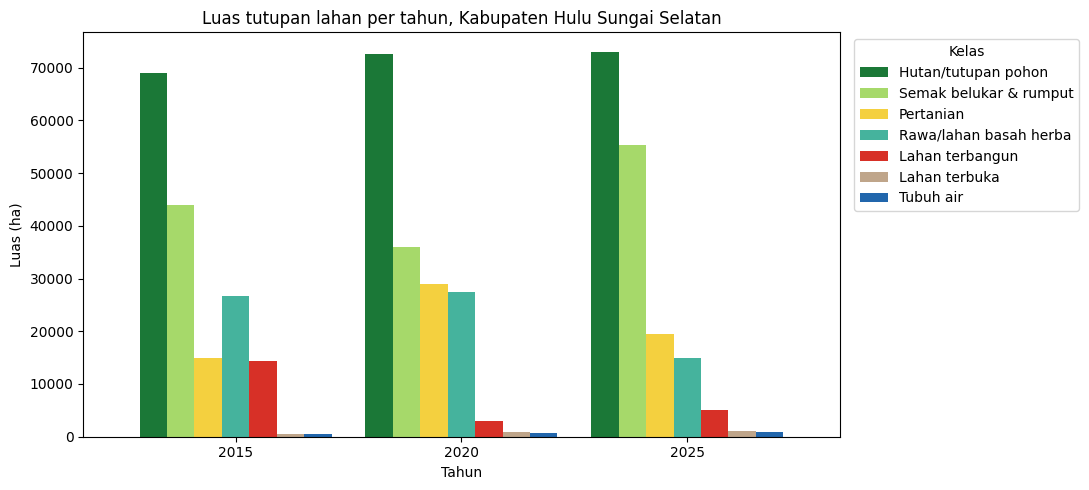

[OK] Tabel tersimpan: luas_tutupan_lahan.csv


In [41]:
# Sel 8 - Luas per kelas per tahun
def hitung_luas_grup(citra_kode):
    """Luas (ha) per nilai piksel. Dipakai juga oleh Sel 9, 10, dan 12."""
    return ee.Image.pixelArea().divide(1e4).addBands(citra_kode).reduceRegion(
        reducer=ee.Reducer.sum().group(groupField=1, groupName="kelas"),
        geometry=aoi, scale=SKALA, crs=CRS_EKSPOR, maxPixels=1e13, tileScale=4)


luas_per_tahun = {}
for tahun in TAHUN_ANALISIS:
    hasil_luas = ambil_info(hitung_luas_grup(KLASIFIKASI[tahun]), f"menghitung luas kelas {tahun}")
    luas_per_tahun[tahun] = pd.Series({int(g["kelas"]): g["sum"] for g in hasil_luas["groups"]})
    print(f"[OK] Luas {tahun} selesai")

tabel_ha = pd.DataFrame(luas_per_tahun).reindex(KODE_KELAS).fillna(0.0)
tabel_ha.index = NAMA_KELAS
tabel_ha.index.name = "kelas"
tabel_persen = tabel_ha.div(tabel_ha.sum(), axis=1) * 100

print("Luas per kelas (ha)")
display(tabel_ha.round(2))
print("Luas per kelas (%)")
display(tabel_persen.round(2))

df_luas = pd.concat([tabel_ha.add_suffix("_ha"), tabel_persen.add_suffix("_persen")], axis=1)
HASIL["tabel_ha"] = tabel_ha
HASIL["tabel_persen"] = tabel_persen
HASIL["df_luas"] = df_luas
df_luas.round(2).to_csv("luas_tutupan_lahan.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(11, 5))
tabel_ha.T.plot(kind="bar", ax=ax, color=WARNA_KELAS, width=0.85)
ax.set_title("Luas tutupan lahan per tahun, Kabupaten Hulu Sungai Selatan")
ax.set_xlabel("Tahun")
ax.set_ylabel("Luas (ha)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Kelas", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()
print("[OK] Tabel tersimpan: luas_tutupan_lahan.csv")

In [42]:
# Sel 9 - Matriks perubahan tutupan lahan
def nama_kelas(kode):
    return KELAS[kode]["nama"] if kode in KELAS else f"Kode {kode}"


def citra_transisi(tahun_awal, tahun_akhir):
    """Kode transisi = kelas_awal x 100 + kelas_akhir."""
    return (KLASIFIKASI[tahun_awal].toInt().multiply(100)
            .add(KLASIFIKASI[tahun_akhir].toInt()).rename("kelas").toInt())


def hitung_transisi(tahun_awal, tahun_akhir):
    hasil = ambil_info(hitung_luas_grup(citra_transisi(tahun_awal, tahun_akhir)),
                       f"menghitung transisi {tahun_awal}-{tahun_akhir}")
    baris = []
    for grup in hasil["groups"]:
        kode = int(grup["kelas"])
        baris.append({"kelas_awal": kode // 100, "kelas_akhir": kode % 100, "luas_ha": grup["sum"]})
    return pd.DataFrame(baris, columns=["kelas_awal", "kelas_akhir", "luas_ha"])


tahun_pertama = TAHUN_ANALISIS[0]
tahun_terakhir = TAHUN_ANALISIS[-1]
PASANGAN_TAHUN = list(dict.fromkeys(
    [(tahun_pertama, tahun_terakhir)] + list(zip(TAHUN_ANALISIS, TAHUN_ANALISIS[1:]))))

hasil_transisi = {}
for awal, akhir in PASANGAN_TAHUN:
    df_transisi = hitung_transisi(awal, akhir)
    hasil_transisi[(awal, akhir)] = df_transisi
    df_nama = df_transisi.assign(
        awal_nama=df_transisi["kelas_awal"].map(nama_kelas),
        akhir_nama=df_transisi["kelas_akhir"].map(nama_kelas),
    )
    pivot = (df_nama.pivot_table(index="awal_nama", columns="akhir_nama", values="luas_ha", aggfunc="sum")
             .reindex(index=NAMA_KELAS, columns=NAMA_KELAS).fillna(0.0).round(2))
    pivot.index.name = f"Kelas {awal}"
    pivot.columns.name = f"Kelas {akhir}"
    print(f"Matriks perubahan {awal} → {akhir} (ha)")
    display(pivot)
    pivot.to_csv(f"matriks_transisi_{awal}_{akhir}.csv", encoding="utf-8-sig")
    if (awal, akhir) == (tahun_pertama, tahun_terakhir):
        df_transisi_utama = pivot

df_utama = hasil_transisi[(tahun_pertama, tahun_terakhir)]
terbesar = df_utama[df_utama["kelas_awal"] != df_utama["kelas_akhir"]].nlargest(5, "luas_ha")
HASIL["df_transisi"] = df_transisi_utama
HASIL["top5"] = terbesar
print(f"5 transisi terbesar {tahun_pertama} → {tahun_terakhir}:")
for _, baris_transisi in terbesar.iterrows():
    print(f"- {nama_kelas(int(baris_transisi['kelas_awal']))} → "
          f"{nama_kelas(int(baris_transisi['kelas_akhir']))}: {baris_transisi['luas_ha']:,.2f} ha")

# Diagram Sankey bersifat opsional, jadi kegagalannya tidak menghentikan notebook.
try:
    import plotly.graph_objects as go

    posisi = {kode: i for i, kode in enumerate(KODE_KELAS)}
    df_sankey = df_utama[df_utama["kelas_awal"].isin(KODE_KELAS) & df_utama["kelas_akhir"].isin(KODE_KELAS)]
    fig_sankey = go.Figure(go.Sankey(
        node={"label": [f"{n} {tahun_pertama}" for n in NAMA_KELAS] + [f"{n} {tahun_terakhir}" for n in NAMA_KELAS],
              "color": WARNA_KELAS + WARNA_KELAS, "pad": 12, "thickness": 16},
        link={"source": [posisi[k] for k in df_sankey["kelas_awal"]],
              "target": [posisi[k] + len(KODE_KELAS) for k in df_sankey["kelas_akhir"]],
              "value": df_sankey["luas_ha"].tolist(),
              "color": "rgba(150,150,150,0.35)"},
    ))
    fig_sankey.update_layout(title_text=f"Perubahan tutupan lahan {tahun_pertama}–{tahun_terakhir} (ha)", height=600)
    fig_sankey.show()
except Exception as galat:
    print(f"[PERINGATAN] Diagram Sankey dilewati: {galat}")
print("[OK] Matriks perubahan selesai")

Matriks perubahan 2015 → 2025 (ha)


Kelas 2025,Hutan/tutupan pohon,Semak belukar & rumput,Pertanian,Rawa/lahan basah herba,Lahan terbangun,Lahan terbuka,Tubuh air
Kelas 2015,,,,,,,
Hutan/tutupan pohon,65282.45,1618.57,675.64,92.53,384.22,944.66,59.04
Semak belukar & rumput,3962.62,31090.18,3379.22,4462.81,770.40,0.00,231.27
Pertanian,1091.06,6361.21,5826.48,944.96,519.04,9.00,103.08
Rawa/lahan basah herba,1581.91,12120.45,4053.56,7659.00,1099.59,0.00,159.76
Lahan terbangun,904.62,4051.11,5428.34,1654.58,2296.86,14.85,25.91
Lahan terbuka,207.55,0.18,8.88,0.54,36.94,195.34,1.62
Tubuh air,6.46,155.87,35.85,52.37,0.18,3.33,257.21


Matriks perubahan 2015 → 2020 (ha)


Kelas 2020,Hutan/tutupan pohon,Semak belukar & rumput,Pertanian,Rawa/lahan basah herba,Lahan terbangun,Lahan terbuka,Tubuh air
Kelas 2015,,,,,,,
Hutan/tutupan pohon,65681.60,1589.41,657.28,238.83,170.76,540.11,30.85
Semak belukar & rumput,3877.76,22356.90,7584.50,9652.72,271.11,0.09,153.43
Pertanian,1198.32,3662.80,7615.15,1988.11,292.08,11.79,86.59
Rawa/lahan basah herba,930.87,6318.47,6932.86,11936.33,423.48,0.72,131.54
Lahan terbangun,822.71,1894.41,6173.96,3446.37,1848.13,33.27,157.42
Lahan terbuka,58.49,0.00,7.53,0.36,20.94,362.84,0.90
Tubuh air,29.48,187.11,26.99,100.49,1.53,2.97,162.70


Matriks perubahan 2020 → 2025 (ha)


Kelas 2025,Hutan/tutupan pohon,Semak belukar & rumput,Pertanian,Rawa/lahan basah herba,Lahan terbangun,Lahan terbuka,Tubuh air
Kelas 2020,,,,,,,
Hutan/tutupan pohon,67786.85,2442.77,1131.75,159.36,361.02,681.99,35.49
Semak belukar & rumput,2786.01,27721.78,2265.68,2395.83,586.72,0.00,253.06
Pertanian,1056.45,11902.60,10883.86,3724.34,1191.05,12.97,227.00
Rawa/lahan basah herba,687.44,12601.27,4227.23,8114.99,1594.17,0.00,138.09
Lahan terbangun,178.62,566.71,651.37,334.62,1287.28,8.97,0.45
Lahan terbuka,385.37,0.18,18.70,0.72,63.76,463.25,19.80
Tubuh air,7.64,162.26,229.39,136.93,23.21,0.00,164.01


5 transisi terbesar 2015 → 2025:
- Rawa/lahan basah herba → Semak belukar & rumput: 12,120.45 ha
- Pertanian → Semak belukar & rumput: 6,361.21 ha
- Lahan terbangun → Pertanian: 5,428.34 ha
- Semak belukar & rumput → Rawa/lahan basah herba: 4,462.81 ha
- Rawa/lahan basah herba → Pertanian: 4,053.56 ha


[OK] Matriks perubahan selesai


,kehilangan_tutupan_pohon_ha
tahun,
2001,238.04
2002,413.99
2003,135.01
2004,479.66
2005,272.46
2006,633.18
2007,491.11
2008,812.17
2009,2022.89


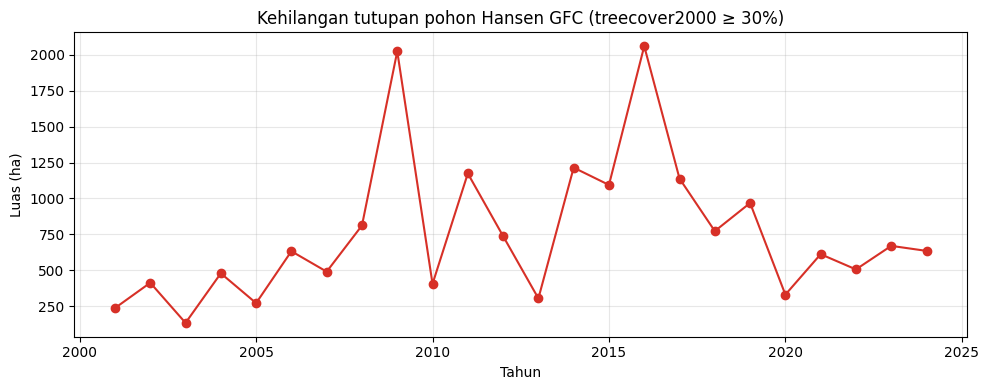

[OK] Total kehilangan 2001–2024: 18,126.30 ha


In [43]:
# Sel 10 - Pembanding Hansen Global Forest Change
hansen = ee.Image("UMD/hansen/global_forest_change_2025_v1_13")
tahun_loss = hansen.select("lossyear")
mask_hansen = hansen.select("treecover2000").gte(30).And(tahun_loss.gte(1)).And(tahun_loss.lte(24))

hasil_hansen = ambil_info(hitung_luas_grup(tahun_loss.updateMask(mask_hansen).rename("kelas")),
                          "menghitung kehilangan tutupan pohon Hansen")
kehilangan = pd.Series({2000 + int(g["kelas"]): g["sum"] for g in hasil_hansen["groups"]}, dtype=float)
kehilangan = kehilangan.reindex(range(2001, 2025)).fillna(0.0)
kehilangan.index.name = "tahun"
kehilangan.name = "kehilangan_tutupan_pohon_ha"

df_hansen = kehilangan.to_frame()
HASIL["df_hansen"] = df_hansen
display(df_hansen.round(2))
kehilangan.round(2).to_csv("hansen_kehilangan_ha.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(kehilangan.index, kehilangan.values, marker="o", color="#D73027")
ax.set_title("Kehilangan tutupan pohon Hansen GFC (treecover2000 ≥ 30%)")
ax.set_xlabel("Tahun")
ax.set_ylabel("Luas (ha)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"[OK] Total kehilangan 2001–2024: {kehilangan.sum():,.2f} ha")

In [44]:
# Sel 11 - Peta interaktif hasil analisis
citra_berubah = KLASIFIKASI[tahun_pertama].neq(KLASIFIKASI[tahun_terakhir]).rename("berubah").toByte()

peta = geemap.Map(basemap="Esri.WorldImagery")
peta.centerObject(fc_batas, 10)
for tahun in TAHUN_ANALISIS:
    peta.addLayer(komposit[tahun], VIS_TRUE, f"Komposit {tahun}", False)
for tahun in TAHUN_ANALISIS:
    peta.addLayer(KLASIFIKASI[tahun], VIS_KELAS, f"Tutupan lahan {tahun}", tahun == tahun_terakhir)
peta.addLayer(citra_berubah, {"min": 0, "max": 1, "palette": ["D9D9D9", "D73027"]},
              f"Perubahan {tahun_pertama}-{tahun_terakhir} (merah = berubah)", False)
peta.addLayer(fc_batas.style(color="000000", fillColor="00000000", width=2), {}, "Batas wilayah")
peta.add_legend(title="Tutupan lahan", legend_dict=dict(zip(NAMA_KELAS, WARNA_KELAS)), position="bottomright")
peta

Map(center=[-2.7284204710302147, 115.20695676099925], controls=(WidgetControl(options=['position', 'transparen…

In [45]:
# Sel 12 - Ekspor raster dan tabel ke Google Drive
def fc_luas(tahun):
    """Tabel luas per kelas sebagai FeatureCollection server-side."""
    def ke_fitur(grup):
        grup = ee.Dictionary(grup)
        return ee.Feature(None, {"tahun": tahun, "kelas": grup.get("kelas"), "luas_ha": grup.get("sum")})
    return ee.FeatureCollection(ee.List(hitung_luas_grup(KLASIFIKASI[tahun]).get("groups")).map(ke_fitur))


def fc_transisi(tahun_awal, tahun_akhir):
    """Tabel transisi sebagai FeatureCollection server-side."""
    def ke_fitur(grup):
        grup = ee.Dictionary(grup)
        kode = ee.Number(grup.get("kelas"))
        return ee.Feature(None, {
            "tahun_awal": tahun_awal, "tahun_akhir": tahun_akhir,
            "kode_transisi": kode,
            "kelas_awal": kode.divide(100).floor(),
            "kelas_akhir": kode.mod(100),
            "luas_ha": grup.get("sum"),
        })
    hasil = hitung_luas_grup(citra_transisi(tahun_awal, tahun_akhir))
    return ee.FeatureCollection(ee.List(hasil.get("groups")).map(ke_fitur))


def gabung_fc(daftar_fc):
    gabungan = daftar_fc[0]
    for fc in daftar_fc[1:]:
        gabungan = gabungan.merge(fc)
    return gabungan


daftar_task = []

# Nilai 0 pada GeoTIFF berarti di luar wilayah/tanpa data, karena kode kelas mulai dari 1.
for tahun in TAHUN_ANALISIS:
    nama_berkas = f"HSS_tutupan_lahan_{tahun}_{SENSOR}_{SKALA}m"
    daftar_task.append(ee.batch.Export.image.toDrive(
        image=KLASIFIKASI[tahun], description=nama_berkas, folder=FOLDER_DRIVE,
        fileNamePrefix=nama_berkas, region=aoi, scale=SKALA, crs=CRS_EKSPOR,
        maxPixels=1e13, fileFormat="GeoTIFF"))

daftar_task.append(ee.batch.Export.table.toDrive(
    collection=gabung_fc([fc_luas(t) for t in TAHUN_ANALISIS]),
    description="HSS_tabel_luas", folder=FOLDER_DRIVE, fileNamePrefix="HSS_tabel_luas",
    fileFormat="CSV", selectors=["tahun", "kelas", "luas_ha"]))

daftar_task.append(ee.batch.Export.table.toDrive(
    collection=gabung_fc([fc_transisi(a, b) for a, b in PASANGAN_TAHUN]),
    description="HSS_tabel_transisi", folder=FOLDER_DRIVE, fileNamePrefix="HSS_tabel_transisi",
    fileFormat="CSV",
    selectors=["tahun_awal", "tahun_akhir", "kode_transisi", "kelas_awal", "kelas_akhir", "luas_ha"]))

for task in daftar_task:
    task.start()
    print(f"[OK] Task dimulai | ID: {task.id}")


def cek_status():
    """Jalankan cek_status() di sel baru untuk melihat perkembangan ekspor."""
    for task in daftar_task:
        try:
            status = task.status()
            print(f"{status.get('description')}: {status.get('state')} {status.get('error_message', '')}")
        except Exception as galat:
            print(f"[PERINGATAN] Status task {task.id} gagal dibaca: {galat}")


cek_status()

[OK] Task dimulai | ID: ARUNJF5KMBI424RCJAVUFAEC
[OK] Task dimulai | ID: IJ7P4JNHVL73EXBD7NJ5EWBZ
[OK] Task dimulai | ID: D3HDBKYB4NCKOR2RYD26KIK3
[OK] Task dimulai | ID: JRUPBEU4O76FUO5G67O37KSC
[OK] Task dimulai | ID: JJ2A36YRG4HJQWB6TTWRNQMQ
HSS_tutupan_lahan_2015_landsat_30m: READY 
HSS_tutupan_lahan_2020_landsat_30m: READY 
HSS_tutupan_lahan_2025_landsat_30m: READY 
HSS_tabel_luas: READY 
HSS_tabel_transisi: READY 


In [ ]:
# Sel 13 - Laporan PDF otomatis
import io
import os
import shutil
import textwrap
import time

import requests
from google.colab import drive, files
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import Patch
from PIL import Image as PILImage

UKURAN_A4 = (8.27, 11.69)
TAHUN_PERTAMA = TAHUN_ANALISIS[0]
TAHUN_TERAKHIR = TAHUN_ANALISIS[-1]
halaman_gagal = []
nomor_halaman = [0]


def halaman_baru(judul=None):
    fig = plt.figure(figsize=UKURAN_A4)
    if judul:
        fig.text(0.08, 0.95, judul, fontsize=15, fontweight="bold", va="top")
    return fig


def buat_halaman(pdf, nama, fungsi):
    """Satu halaman gagal tidak menggagalkan seluruh PDF."""
    try:
        fig = fungsi()
        nomor_halaman[0] += 1
        fig.text(0.08, 0.03, f"{JUDUL_LAPORAN} | {NAMA_PENYUSUN}", fontsize=7, color="#555555")
        fig.text(0.92, 0.03, f"Halaman {nomor_halaman[0]}", fontsize=7, color="#555555", ha="right")
        pdf.savefig(fig)
        plt.close(fig)
        print(f"[OK] Halaman selesai: {nama}")
    except Exception as galat:
        halaman_gagal.append(f"{nama}: {galat}")
        plt.close("all")
        print(f"[PERINGATAN] Halaman gagal: {nama}: {galat}")


def tulis_paragraf(fig, y, teks, lebar=88, ukuran=10):
    """Tulis teks terbungkus dan kembalikan posisi y berikutnya."""
    langkah = ukuran * 1.45 / (72 * UKURAN_A4[1])
    for baris in textwrap.wrap(teks, lebar):
        fig.text(0.08, y, baris, fontsize=ukuran, va="top")
        y -= langkah
    return y - langkah * 0.6


def gambar_tabel(fig, y_atas, data, kolom, lebar_kolom, ukuran=8, tinggi_baris=0.024):
    """Gambar tabel selebar halaman dan kembalikan posisi y di bawahnya."""
    tinggi = (len(data) + 1) * tinggi_baris
    ax = fig.add_axes([0.08, y_atas - tinggi, 0.84, tinggi])
    ax.axis("off")
    tabel = ax.table(cellText=data, colLabels=kolom, colWidths=lebar_kolom, cellLoc="center", bbox=[0, 0, 1, 1])
    tabel.auto_set_font_size(False)
    tabel.set_fontsize(ukuran)
    for (baris, _), sel in tabel.get_celld().items():
        sel.set_edgecolor("#999999")
        sel.set_linewidth(0.4)
        if baris == 0:
            sel.set_facecolor("#E8E8E8")
            sel.set_text_props(fontweight="bold")
    return y_atas - tinggi - 0.025


def ambil_peta(citra_visual):
    """Unduh thumbnail peta dengan garis batas. Mengembalikan None bila tetap gagal."""
    for percobaan in range(3):
        try:
            garis = ee.Image().byte().paint(fc_batas, 1, 2).visualize(palette=["000000"])
            gabung = ee.ImageCollection([citra_visual, garis]).mosaic()
            url = gabung.getThumbURL({"region": aoi.bounds(), "dimensions": 1000, "format": "png"})
            respons = requests.get(url, timeout=300)
            respons.raise_for_status()
            return PILImage.open(io.BytesIO(respons.content)).convert("RGBA")
        except Exception as galat:
            print(f"[PERINGATAN] Unduh peta percobaan {percobaan + 1} gagal: {galat}")
            time.sleep(5)
    return None


def tampilkan_peta(fig, posisi, gambar):
    ax = fig.add_axes(posisi)
    ax.axis("off")
    if gambar is None:
        ax.text(0.5, 0.5, "Peta gagal dimuat, jalankan ulang Sel 13", ha="center", va="center", fontsize=12)
    else:
        ax.imshow(gambar)
    return ax


def angka(nilai, desimal=2):
    return f"{nilai:,.{desimal}f}"


def hal_sampul():
    fig = halaman_baru()
    fig.text(0.5, 0.72, "\n".join(textwrap.wrap(JUDUL_LAPORAN, 42)), fontsize=22, fontweight="bold",
             ha="center", va="center")
    fig.text(0.5, 0.60, "Kabupaten Hulu Sungai Selatan, Kalimantan Selatan", fontsize=13, ha="center")
    fig.text(0.5, 0.56, f"Periode {TAHUN_PERTAMA} - {TAHUN_TERAKHIR} | Sensor {SENSOR} | Skala {SKALA} m",
             fontsize=11, ha="center")
    fig.text(0.5, 0.36, NAMA_PENYUSUN, fontsize=13, fontweight="bold", ha="center")
    fig.text(0.5, 0.33, INSTANSI, fontsize=11, ha="center")
    fig.text(0.5, 0.29, datetime.date.today().strftime("Dibuat %d-%m-%Y"), fontsize=10, ha="center")
    return fig


def hal_metode():
    fig = halaman_baru("Data dan Metode")
    nama_sensor = ("Landsat Collection 2 Level 2" if SENSOR == "landsat"
                   else "Sentinel-2 SR Harmonized dengan Cloud Score+")
    mask_awan = ("mask QA_PIXEL (awan, dilated cloud, bayangan, cirrus)" if SENSOR == "landsat"
                 else "ambang Cloud Score+ cs_cdf >= 0,60")
    sumber_label = ("ESA WorldCover v200 dengan piksel homogen" if MODE_SAMPEL == "otomatis"
                    else f"asset sampel manual {ASSET_SAMPEL}")
    df_sampel = HASIL["df_sampel"]
    y = 0.90
    y = tulis_paragraf(fig, y, (
        f"Analisis memakai citra {nama_sensor} pada bulan {BULAN_AWAL} sampai {BULAN_AKHIR} untuk tahun "
        f"{', '.join(str(t) for t in TAHUN_ANALISIS)}. Piksel berawan dihapus dengan {mask_awan}. Komposit dibuat "
        "dengan median tahunan, lalu celah yang tersisa diisi median tahun sebelumnya sampai tahun sesudahnya."))
    y = tulis_paragraf(fig, y, (
        f"Variabel klasifikasi berjumlah {len(BANDS)}: enam band reflektansi, NDVI, NDWI, MNDWI, NDBI, EVI, "
        "elevasi, dan kemiringan lereng dari SRTM."))
    y = tulis_paragraf(fig, y, (
        f"Klasifikasi memakai Random Forest {JUMLAH_POHON_RF} pohon yang dilatih pada komposit {TAHUN_ACUAN}. "
        f"Label berasal dari {sumber_label}. Data dibagi menjadi {int(df_sampel['latih'].sum())} sampel latih dan "
        f"{int(df_sampel['uji'].sum())} sampel uji. Hasil diperhalus dengan focalMode radius 1 piksel."))
    y = tulis_paragraf(fig, y, (
        f"Skala analisis {SKALA} m dan sistem koordinat ekspor {CRS_EKSPOR}. Batas wilayah berasal dari "
        f"{HASIL['sumber_batas']} dengan luas {angka(HASIL['luas_wilayah_km2'], 1)} km2."))
    y -= 0.015
    fig.text(0.08, y, "Jumlah citra dan piksel valid per tahun", fontsize=11, fontweight="bold", va="top")
    df = HASIL["df_komposit"]
    data = [[str(t), str(int(b["jumlah_citra"])), angka(b["valid_tahun_ini_%"]), angka(b["valid_setelah_diisi_%"])]
            for t, b in df.iterrows()]
    y = gambar_tabel(fig, y - 0.03, data, ["Tahun", "Jumlah citra", "Valid tahun ini (%)", "Valid setelah diisi (%)"],
                     [0.16, 0.2, 0.32, 0.32], ukuran=9)
    fig.text(0.08, y, "Jumlah sampel per kelas", fontsize=11, fontweight="bold", va="top")
    data = [[n, str(int(b["latih"])), str(int(b["uji"]))] for n, b in df_sampel.iterrows()]
    gambar_tabel(fig, y - 0.03, data, ["Kelas", "Latih", "Uji"], [0.6, 0.2, 0.2], ukuran=8)
    return fig


def hal_lokasi():
    fig = halaman_baru(f"Peta Lokasi (True Color {TAHUN_TERAKHIR})")
    tulis_paragraf(fig, 0.90, f"Luas wilayah menurut batas yang dipakai: {angka(HASIL['luas_wilayah_km2'], 1)} km2.")
    citra = komposit[TAHUN_TERAKHIR].visualize(bands=VIS_TRUE["bands"], min=VIS_TRUE["min"],
                                               max=VIS_TRUE["max"], gamma=VIS_TRUE["gamma"])
    tampilkan_peta(fig, [0.08, 0.08, 0.84, 0.78], ambil_peta(citra))
    return fig


def hal_peta_kelas(tahun):
    fig = halaman_baru(f"Peta Tutupan Lahan {tahun}")
    citra = KLASIFIKASI[tahun].visualize(min=VIS_KELAS["min"], max=VIS_KELAS["max"], palette=VIS_KELAS["palette"])
    tampilkan_peta(fig, [0.08, 0.20, 0.84, 0.72], ambil_peta(citra))
    fig.legend(handles=[Patch(facecolor=w, edgecolor="#666666", label=n) for n, w in zip(NAMA_KELAS, WARNA_KELAS)],
               loc="lower center", bbox_to_anchor=(0.5, 0.06), ncol=2, fontsize=9, frameon=False)
    return fig


def hal_luas():
    fig = halaman_baru("Luas Tutupan Lahan")
    ha = HASIL["tabel_ha"]
    persen = HASIL["tabel_persen"]
    kolom = ["Kelas"]
    for tahun in TAHUN_ANALISIS:
        kolom += [f"{tahun} (ha)", f"{tahun} (%)"]
    data = []
    for nama in NAMA_KELAS:
        baris = [nama]
        for tahun in TAHUN_ANALISIS:
            baris += [angka(ha.loc[nama, tahun]), angka(persen.loc[nama, tahun])]
        data.append(baris)
    baris_total = ["Total"]
    for tahun in TAHUN_ANALISIS:
        baris_total += [angka(ha[tahun].sum()), "100,00"]
    data.append(baris_total)
    sisa = 0.66 / (2 * len(TAHUN_ANALISIS))
    y = gambar_tabel(fig, 0.90, data, kolom, [0.34] + [sisa] * (2 * len(TAHUN_ANALISIS)), ukuran=7)
    ax = fig.add_axes([0.11, 0.22, 0.81, y - 0.27])
    ha.T.plot(kind="bar", ax=ax, color=WARNA_KELAS, width=0.85, legend=False)
    ax.set_xlabel("Tahun")
    ax.set_ylabel("Luas (ha)")
    ax.tick_params(axis="x", rotation=0)
    fig.legend(handles=[Patch(facecolor=w, label=n) for n, w in zip(NAMA_KELAS, WARNA_KELAS)],
               loc="lower center", bbox_to_anchor=(0.5, 0.07), ncol=2, fontsize=9, frameon=False)
    return fig


def hal_akurasi():
    fig = halaman_baru("Akurasi Klasifikasi")
    y = 0.90
    y = tulis_paragraf(fig, y, f"Overall accuracy: {HASIL['oa'] * 100:.2f}%. Kappa: {HASIL['kappa'] * 100:.2f}%.", ukuran=11)
    if MODE_SAMPEL == "otomatis":
        y = tulis_paragraf(fig, y, ("Catatan: akurasi ini hanya mengukur kecocokan dengan ESA WorldCover pada komposit "
                                    f"{TAHUN_ACUAN}, bukan kebenaran lapangan."), ukuran=9)
    df = HASIL["df_akurasi"]
    data = [[n, f"{b['producers_accuracy'] * 100:.2f}", f"{b['users_accuracy'] * 100:.2f}"] for n, b in df.iterrows()]
    y = gambar_tabel(fig, y - 0.01, data, ["Kelas", "Producer's accuracy (%)", "User's accuracy (%)"], [0.44, 0.28, 0.28])
    matriks = HASIL["df_konfusi"].to_numpy(dtype=float)
    ax = fig.add_axes([0.2, 0.09, 0.64, y - 0.14])
    ax.imshow(matriks, cmap="Greens")
    ax.set_xticks(range(len(KODE_KELAS)))
    ax.set_yticks(range(len(KODE_KELAS)))
    ax.set_xticklabels(KODE_KELAS)
    ax.set_yticklabels(KODE_KELAS)
    ax.set_xlabel("Kelas hasil klasifikasi")
    ax.set_ylabel("Kelas acuan")
    ax.set_title("Matriks konfusi data uji (kode kelas)", fontsize=10)
    batas = matriks.max() / 2 if matriks.max() else 0
    for i in range(matriks.shape[0]):
        for j in range(matriks.shape[1]):
            ax.text(j, i, f"{matriks[i, j]:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if matriks[i, j] > batas else "black")
    return fig


def hal_perubahan():
    fig = halaman_baru(f"Perubahan Tutupan Lahan {TAHUN_PERTAMA} - {TAHUN_TERAKHIR}")
    pivot = HASIL["df_transisi"]
    kolom = ["Awal \\ Akhir"] + [str(k) for k in KODE_KELAS]
    data = [[str(k)] + [f"{v:,.0f}" for v in pivot.iloc[i].tolist()] for i, k in enumerate(KODE_KELAS)]
    lebar = [0.16] + [0.84 / len(KODE_KELAS)] * len(KODE_KELAS)
    fig.text(0.08, 0.905, "Matriks transisi (ha), baris = kelas awal dan kolom = kelas akhir", fontsize=10,
             fontweight="bold", va="top")
    y = gambar_tabel(fig, 0.88, data, kolom, lebar, ukuran=7, tinggi_baris=0.02)
    keterangan = "Kode: " + "; ".join(f"{k} = {KELAS[k]['nama']}" for k in KODE_KELAS)
    y = tulis_paragraf(fig, y + 0.012, keterangan, lebar=115, ukuran=7.5) - 0.005
    top5 = HASIL["top5"]
    data = [[nama_kelas(int(b["kelas_awal"])), nama_kelas(int(b["kelas_akhir"])), angka(b["luas_ha"])]
            for _, b in top5.iterrows()]
    if data:
        y = gambar_tabel(fig, y, data, ["Kelas awal", "Kelas akhir", "Luas (ha)"], [0.42, 0.42, 0.16], ukuran=8)
    citra = (KLASIFIKASI[TAHUN_PERTAMA].neq(KLASIFIKASI[TAHUN_TERAKHIR]).toByte()
             .visualize(min=0, max=1, palette=["D9D9D9", "D73027"]))
    tampilkan_peta(fig, [0.14, 0.085, 0.72, y - 0.10], ambil_peta(citra))
    fig.legend(handles=[Patch(facecolor="#D9D9D9", label="Tidak berubah"), Patch(facecolor="#D73027", label="Berubah")],
               loc="lower center", bbox_to_anchor=(0.5, 0.045), ncol=2, fontsize=9, frameon=False)
    return fig


def hal_hansen():
    fig = halaman_baru("Pembanding: Hansen Global Forest Change")
    df = HASIL["df_hansen"]
    kolom = df.columns[0]
    y = tulis_paragraf(fig, 0.90, (
        f"Total kehilangan tutupan pohon 2001-2024 pada treecover2000 >= 30% adalah {angka(df[kolom].sum())} ha. "
        f"Puncaknya terjadi pada tahun {int(df[kolom].idxmax())} seluas {angka(df[kolom].max())} ha. Data ini juga "
        "mencakup hilangnya pohon pada kebun, sehingga tidak sama dengan deforestasi."))
    ax = fig.add_axes([0.11, 0.42, 0.81, y - 0.47])
    ax.plot(df.index, df[kolom], marker="o", color="#D73027")
    ax.set_xlabel("Tahun")
    ax.set_ylabel("Kehilangan tutupan pohon (ha)")
    ax.grid(alpha=0.3)
    return fig


def hal_ringkasan():
    fig = halaman_baru("Ringkasan dan Interpretasi")
    ha = HASIL["tabel_ha"]
    awal, akhir = TAHUN_PERTAMA, TAHUN_TERAKHIR
    selisih = ha[akhir] - ha[awal]

    def teks_kelas(nama):
        dasar = ha.loc[nama, awal]
        persen = f" ({selisih[nama] / dasar * 100:+.1f}%)" if dasar > 0 else ""
        return f"{nama}, sebesar {angka(abs(selisih[nama]))} ha{persen}"

    y = tulis_paragraf(fig, 0.90, f"Pertambahan luas terbesar {awal} - {akhir} terjadi pada kelas {teks_kelas(selisih.idxmax())}.")
    y = tulis_paragraf(fig, y, f"Pengurangan luas terbesar terjadi pada kelas {teks_kelas(selisih.idxmin())}.")
    top5 = HASIL["top5"]
    if len(top5):
        pertama = top5.iloc[0]
        y = tulis_paragraf(fig, y, (f"Transisi terbesar adalah {nama_kelas(int(pertama['kelas_awal']))} menjadi "
                                    f"{nama_kelas(int(pertama['kelas_akhir']))} seluas {angka(pertama['luas_ha'])} ha."))
    kelas_hutan = [n for n in NAMA_KELAS if "Hutan" in n]
    ubah_hutan = selisih[kelas_hutan].sum()
    df_h = HASIL["df_hansen"]
    kolom_h = df_h.columns[0]
    tahun_h = min(akhir, 2024)
    loss = df_h.loc[(df_h.index > awal) & (df_h.index <= tahun_h), kolom_h].sum()
    arah = "bertambah" if ubah_hutan >= 0 else "berkurang"
    y = tulis_paragraf(fig, y, (
        f"Luas kelas hutan hasil klasifikasi {arah} {angka(abs(ubah_hutan))} ha pada {awal} - {akhir}. Hansen mencatat "
        f"kehilangan tutupan pohon {angka(loss)} ha pada {awal + 1} - {tahun_h}. Selisih keduanya wajar karena definisi "
        "kelas, metode, dan regenerasi vegetasi berbeda."))
    y = tulis_paragraf(fig, y, f"Akurasi data uji: overall accuracy {HASIL['oa'] * 100:.2f}% dan kappa {HASIL['kappa'] * 100:.2f}%.")
    y -= 0.015
    fig.text(0.08, y, "Keterbatasan", fontsize=12, fontweight="bold", va="top")
    y -= 0.03
    catatan_mode = ("Mode sampel otomatis cocok untuk eksplorasi. Hasil ilmiah final memerlukan sampel manual atau data "
                    "lapangan, karena kebun sawit dan karet bisa tergabung ke kelas hutan."
                    if MODE_SAMPEL == "otomatis" else
                    "Akurasi mode manual bergantung pada mutu dan sebaran titik sampel.")
    for teks in [
        "Tutupan awan: celah diisi median tiga tahun, sehingga sebagian piksel tidak murni mewakili satu tahun.",
        "Rawa musiman: median tahunan merangkum genangan yang berubah, sehingga batas rawa, sawah, dan air bisa bergeser.",
        "Kualitas sampel: akurasi hanya dinilai pada komposit acuan, bukan pada setiap tahun analisis.",
        f"Resolusi piksel: skala {SKALA} m belum tentu menangkap permukiman kecil dan sungai sempit.",
        catatan_mode,
    ]:
        y = tulis_paragraf(fig, y, "- " + teks, ukuran=9.5, lebar=92)
    return fig


NAMA_PDF = f"Laporan_Tutupan_Lahan_HSS_{TAHUN_PERTAMA}_{TAHUN_TERAKHIR}.pdf"
PATH_PDF = os.path.join("/content", NAMA_PDF)

with PdfPages(PATH_PDF) as pdf:
    buat_halaman(pdf, "Sampul", hal_sampul)
    buat_halaman(pdf, "Data dan metode", hal_metode)
    buat_halaman(pdf, "Peta lokasi", hal_lokasi)
    for tahun in TAHUN_ANALISIS:
        buat_halaman(pdf, f"Peta tutupan lahan {tahun}", lambda t=tahun: hal_peta_kelas(t))
    buat_halaman(pdf, "Luas tutupan lahan", hal_luas)
    buat_halaman(pdf, "Akurasi", hal_akurasi)
    buat_halaman(pdf, "Perubahan", hal_perubahan)
    buat_halaman(pdf, "Pembanding Hansen", hal_hansen)
    buat_halaman(pdf, "Ringkasan", hal_ringkasan)

print(f"[OK] PDF dibuat: {PATH_PDF} ({nomor_halaman[0]} halaman)")
if halaman_gagal:
    print("[PERINGATAN] Halaman yang gagal:")
    for catatan in halaman_gagal:
        print(" -", catatan)

try:
    drive.mount("/content/drive")
    folder_tujuan = os.path.join("/content/drive/MyDrive", FOLDER_DRIVE)
    os.makedirs(folder_tujuan, exist_ok=True)
    shutil.copy(PATH_PDF, folder_tujuan)
    print(f"[OK] PDF tersalin ke {folder_tujuan}")
except Exception as galat:
    print(f"[PERINGATAN] Salin ke Drive gagal, PDF tetap ada di {PATH_PDF}: {galat}")

try:
    files.download(PATH_PDF)
except Exception as galat:
    print(f"[PERINGATAN] Unduh otomatis gagal, ambil PDF dari panel Files: {galat}")

[OK] Halaman selesai: Sampul
[OK] Halaman selesai: Data dan metode
[OK] Halaman selesai: Peta lokasi
[OK] Halaman selesai: Peta tutupan lahan 2015
[OK] Halaman selesai: Peta tutupan lahan 2020
[OK] Halaman selesai: Peta tutupan lahan 2025
[OK] Halaman selesai: Luas tutupan lahan
[OK] Halaman selesai: Akurasi


## Sel 14 - Penutup: membuka hasil dan menjalankan ulang

**Laporan PDF.** Berkas `Laporan_Tutupan_Lahan_HSS_<tahun_pertama>_<tahun_terakhir>.pdf` terunduh otomatis ke komputer. Salinannya ada di Google Drive pada folder `MyDrive/GEE_HSS_Tutupan_Lahan`. Bila keduanya gagal, ambil dari panel **Files** di kiri Colab (folder `/content`), klik kanan, lalu **Download**.

**Data GeoTIFF dan CSV.** Berkas muncul di folder Drive yang sama setelah task Sel 12 selesai. Pantau dengan menjalankan `cek_status()` di sel baru, atau buka `code.earthengine.google.com/tasks`.

**Menjalankan ulang dengan parameter lain.** Ubah nilai di bagian PARAMETER pada Sel 1, misalnya tahun, sensor, atau bulan. Lalu pilih **Runtime > Run all**. Bila hanya peta PDF yang gagal dimuat, cukup jalankan ulang Sel 13.